# Experiment 10: Hidden layer width

Card: [exp10_width.md](../../experiments/exp10_width.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import INK, SURFACE, TEXT, style_axis
from ashrae.tracking import session_runs
from src.data import fold_loaders
from src.networks import MeterMLP
from src.runs import finished_keys, fold_table, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp10_width"
EMB_DIM = 12  # picked in exp03
LR = 1e-2  # best with BatchNorm in exp09
REFERENCE_WIDTH = 64
if SMOKE:
    EXPERIMENT = "ashrae-mlp-width-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    WIDTHS = [128]
    # width 64 with BatchNorm at lr 1e-2; None: the latest session
    REFERENCE = ("ashrae-mlp-batch-norm-smoke", None)
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-width"
    TRAIN = False  # the runs below are from 2026-10-12; True resumes this session, retraining unfinished runs
    SESSION = "2026-10-12 22:43:11"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WIDTHS = [128, 256, 512]
    REFERENCE = ("ashrae-mlp-batch-norm", "2026-10-12 21:52:51")  # exp09
    FIGURE = "../../figures/exp10_width.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/12 22:43:12 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-width' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-width', session 2026-10-12 22:43:11


## Training


In [2]:
def n_params(n_inputs, width):
    """Parameters of the hidden and output layers; the embedding doesn't depend on width."""
    net = MeterMLP(n_inputs + EMB_DIM, batch_norm=True, width=width)
    return sum(p.numel() for p in net.parameters())


def scores():
    ref = session_runs(*REFERENCE)
    ref = ref[ref.lr.astype(float) == LR].assign(width=REFERENCE_WIDTH)
    keys = {"width": int, "params.n_inputs": int}
    results = session_scores(experiment, keys, FOLD_NAMES, [ref])
    results["n_params"] = [
        n_params(int(n), w) for n, w in zip(results["params.n_inputs"], results.width)
    ]
    return results

In [3]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = (
        set()
        if SESSION is None
        else finished_keys(scores().query("width != @REFERENCE_WIDTH"), ["width", "fold"])
    )

    for width in WIDTHS:
        fit_folds(
            experiment,
            folds,
            lambda: MeterMLP(
                n_features, n_buildings, emb_dim=EMB_DIM, batch_norm=True, width=width
            ),
            f"mlp_4out_emb_bn | width {width}",
            done=done,
            key=(width,),
            epochs=EPOCHS,
            lr=LR,
            tags={"model": "mlp_4out_emb_bn", "width": str(width)},
            params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM, "width": width},
        )

mlp_4out_emb_bn | width 128 | Jan–Mar: 100%|██████████| 19560/19560 [01:33<00:00, 209.88batch/s, epoch 40, val 1.4135, best 1.3920 at 35]
mlp_4out_emb_bn | width 128 | Apr–Jun: 100%|██████████| 19560/19560 [01:36<00:00, 203.17batch/s, epoch 40, val 1.2207, best 1.1975 at 14]
mlp_4out_emb_bn | width 128 | Jul–Sep: 100%|██████████| 19560/19560 [01:34<00:00, 207.25batch/s, epoch 40, val 1.0184, best 1.0039 at 27]
mlp_4out_emb_bn | width 128 | Oct–Dec: 100%|██████████| 19560/19560 [01:35<00:00, 204.67batch/s, epoch 40, val 1.0970, best 1.0850 at 22]
mlp_4out_emb_bn | width 256 | Jan–Mar: 100%|██████████| 19560/19560 [01:34<00:00, 207.68batch/s, epoch 40, val 1.4433, best 1.3936 at 25]
mlp_4out_emb_bn | width 256 | Apr–Jun: 100%|██████████| 19560/19560 [01:37<00:00, 200.08batch/s, epoch 40, val 1.2386, best 1.1999 at 15]
mlp_4out_emb_bn | width 256 | Jul–Sep: 100%|██████████| 19560/19560 [01:36<00:00, 202.95batch/s, epoch 40, val 1.0427, best 1.0118 at 19]
mlp_4out_emb_bn | width 256 | Oct–

## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "n_params": "parameters without embedding",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
table, by_width = fold_table(results, "width", columns, FOLD_NAMES)
display(table.round(3))

MLflow session 2026-10-12 22:43:11: 16 runs, with the reused ones


"RMSLE at the best epoch, all rows unless noted",Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",best epoch,training,parameters without embedding,seconds per epoch,minutes to best epoch
width,,,,,,,,,,,
64,1.386,1.195,1.008,1.085,1.168,0.912,35.25,0.761,7620.0,2.098,1.232
128,1.392,1.198,1.004,1.085,1.170,0.908,24.50,0.750,23428.0,2.192,0.891
256,1.394,1.200,1.012,1.090,1.174,0.911,15.75,0.748,79620.0,2.199,0.575
512,1.395,1.196,1.013,1.091,1.174,0.910,11.75,0.740,290308.0,2.505,0.484


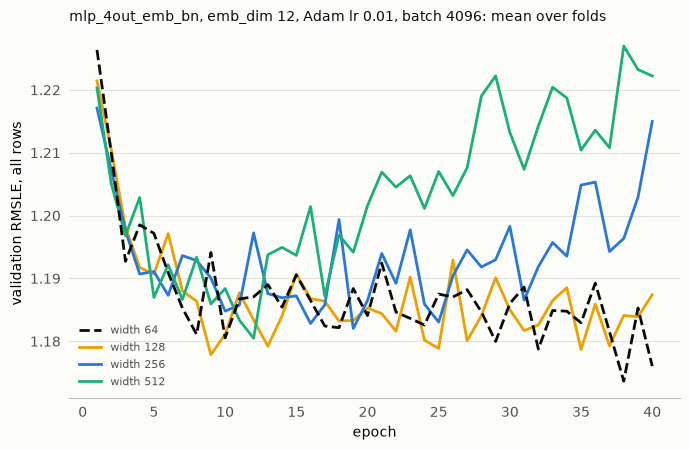

In [5]:
SHADES = {128: "#eda100", 256: "#2a78d6", 512: "#1baf7a"}

fig, ax = plt.subplots(figsize=(7, 4.6), facecolor=SURFACE)
for width, runs in results.groupby("width"):
    curve = pd.DataFrame(
        runs.val_curve.tolist()
    ).mean()  # mean over folds; a diverged run is shorter
    reference = width == REFERENCE_WIDTH
    ax.plot(
        np.arange(1, len(curve) + 1),
        curve,
        lw=2,
        color=INK if reference else SHADES[width],
        ls="--" if reference else "-",
        zorder=3 if reference else 2,  # width 64 on top
        label=f"width {width}",
    )
ax.set(xlabel="epoch", ylabel="validation RMSLE, all rows")
ax.set_title(
    f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, Adam lr {LR:g}, batch 4096: mean over folds",
    loc="left",
    color=INK,
    fontsize=10,
)
style_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=TEXT)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("width != @REFERENCE_WIDTH").run_id:
        experiment.client.log_artifact(run_id, FIGURE)